# Data Mining Lab Assignment: Book Recommender System using a Medallion Data Lake

**Objective:** Take the raw, messy Book-Crossing dataset through a **Bronze → Silver → Gold** Medallion Data Lake pipeline, and use the final Gold layer data to build an **Item-Based Collaborative Filtering** recommender system that suggests books to users.

---
## Step 1: Set Up the Data Lake and Build the Bronze Layer

In this step, we:
1. Create the `bronze/`, `silver/`, and `gold/` folders.
2. Download and extract the Book-Crossing dataset (`book-crossings.zip`) if it is not already present locally.
3. Load the three raw CSV files (`BX-Users.csv`, `BX-Books.csv`, `BX-Book-Ratings.csv`) using semicolon separators (`;`) and `latin-1` encoding.
4. Add an `ingestion_timestamp` column to each table and save them untouched as Parquet files in `bronze/`.

In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

# 1. Create Medallion folders
for folder in ['bronze', 'silver', 'gold']:
    Path(folder).mkdir(parents=True, exist_ok=True)

# 2. Download & extract dataset if not already present
data_dir = Path('book-crossings')
if not (data_dir / 'BX-Users.csv').exists():
    zip_path = Path('book-crossings.zip')
    url = 'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip'
    print(f'Downloading {url} ...')
    urllib.request.urlretrieve(url, zip_path)
    data_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(data_dir)
    print('Download and extraction complete.')
else:
    print('Raw CSV files already present in book-crossings/.')

Raw CSV files already present in book-crossings/.


In [2]:
# 3. Load raw files as-is (semicolon separator, latin-1 encoding)
ingestion_ts = pd.Timestamp.now(tz='UTC')

raw_users = pd.read_csv(
    data_dir / 'BX-Users.csv',
    sep=';',
    encoding='latin-1',
    on_bad_lines='skip',
    low_memory=False
)
raw_books = pd.read_csv(
    data_dir / 'BX-Books.csv',
    sep=';',
    encoding='latin-1',
    on_bad_lines='skip',
    low_memory=False
)
raw_ratings = pd.read_csv(
    data_dir / 'BX-Book-Ratings.csv',
    sep=';',
    encoding='latin-1',
    on_bad_lines='skip',
    low_memory=False
)

# 4. Add ingestion_timestamp and save untouched to bronze/ as Parquet
for name, df in [('users', raw_users), ('books', raw_books), ('book_ratings', raw_ratings)]:
    bronze_df = df.copy()
    bronze_df['ingestion_timestamp'] = ingestion_ts
    out_path = Path('bronze') / f'{name}.parquet'
    bronze_df.to_parquet(out_path, index=False)
    print(f'Saved {out_path} | shape={bronze_df.shape}')

Saved bronze\users.parquet | shape=(278858, 4)
Saved bronze\books.parquet | shape=(271360, 9)


Saved bronze\book_ratings.parquet | shape=(1149780, 4)


---
## Step 2: Explore the Bronze Data (EDA)

We read the Bronze Parquet tables back and inspect:
- Shape, data types, and missing-value counts
- Distribution of ratings (explicit vs implicit `0`)
- Distribution of user ages and publication years (checking for impossible values)
- Number of ratings per user and per book
- Matrix sparsity

In [3]:
# Read Bronze tables back
b_users = pd.read_parquet('bronze/users.parquet')
b_books = pd.read_parquet('bronze/books.parquet')
b_ratings = pd.read_parquet('bronze/book_ratings.parquet')

for name, df in [('Users', b_users), ('Books', b_books), ('Book-Ratings', b_ratings)]:
    print(f'=== {name} ===')
    print(f'Shape: {df.shape}')
    print('Data types & Missing values:')
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing_count': df.isna().sum(),
        'missing_pct': (df.isna().mean() * 100).round(2)
    })
    print(summary)
    print(f'Exact duplicate rows: {df.duplicated().sum()}')
    print()

=== Users ===
Shape: (278858, 4)
Data types & Missing values:
                                   dtype  missing_count  missing_pct
User-ID                            int64              0         0.00
Location                             str              0         0.00
Age                              float64         110762        39.72
ingestion_timestamp  datetime64[us, UTC]              0         0.00
Exact duplicate rows: 0

=== Books ===
Shape: (271360, 9)
Data types & Missing values:
                                   dtype  missing_count  missing_pct
ISBN                                 str              0          0.0
Book-Title                           str              0          0.0
Book-Author                          str              2          0.0
Year-Of-Publication                  str              0          0.0
Publisher                            str              2          0.0
Image-URL-S                          str              0          0.0
Image-URL-M            

Exact duplicate rows: 0

=== Book-Ratings ===
Shape: (1149780, 4)
Data types & Missing values:
                                   dtype  missing_count  missing_pct
User-ID                            int64              0          0.0
ISBN                                 str              0          0.0
Book-Rating                        int64              0          0.0
ingestion_timestamp  datetime64[us, UTC]              0          0.0


Exact duplicate rows: 0



Total ratings: 1,149,780
Implicit ratings (0): 716,109 (62.28%)
Explicit ratings (1-10): 433,671 (37.72%)

Rating value counts:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


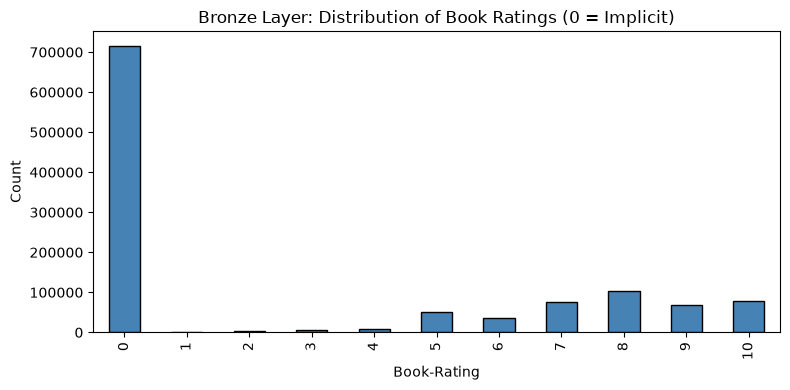

In [4]:
# Distribution of ratings
rating_counts = b_ratings['Book-Rating'].value_counts().sort_index()
zero_ratings = int(rating_counts.get(0, 0))
total_ratings = len(b_ratings)
print(f'Total ratings: {total_ratings:,}')
print(f'Implicit ratings (0): {zero_ratings:,} ({zero_ratings / total_ratings * 100:.2f}%)')
print(f'Explicit ratings (1-10): {total_ratings - zero_ratings:,} ({(total_ratings - zero_ratings) / total_ratings * 100:.2f}%)')
print('\nRating value counts:')
print(rating_counts)

fig, ax = plt.subplots(figsize=(8, 4))
rating_counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Bronze Layer: Distribution of Book Ratings (0 = Implicit)')
ax.set_xlabel('Book-Rating')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

--- User Age Statistics ---
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Ages < 5: 882 | Ages > 100: 366 | Null ages: 110,762

--- Publication Year Statistics ---


Non-numeric years: 3 | Year == 0: 4,618 | Future years (>2026): 11
count    266728.000000
mean       1993.688068
std           8.321611
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Of-Publication, dtype: float64


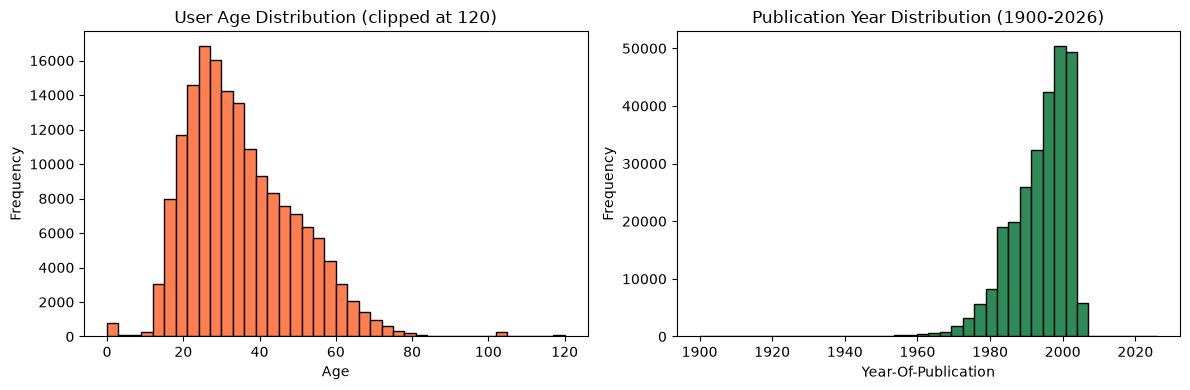

In [5]:
# Distribution of user ages and publication years
print('--- User Age Statistics ---')
print(b_users['Age'].describe())
invalid_age_low = (b_users['Age'] < 5).sum()
invalid_age_high = (b_users['Age'] > 100).sum()
print(f'Ages < 5: {invalid_age_low:,} | Ages > 100: {invalid_age_high:,} | Null ages: {b_users["Age"].isna().sum():,}')

print('\n--- Publication Year Statistics ---')
years_num = pd.to_numeric(b_books['Year-Of-Publication'], errors='coerce')
non_numeric_years = years_num.isna().sum() - b_books['Year-Of-Publication'].isna().sum()
zero_years = (years_num == 0).sum()
future_years = (years_num > 2026).sum()
print(f'Non-numeric years: {non_numeric_years:,} | Year == 0: {zero_years:,} | Future years (>2026): {future_years:,}')
print(years_num[(years_num > 0) & (years_num <= 2026)].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
b_users['Age'].dropna().clip(0, 120).plot(kind='hist', bins=40, ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('User Age Distribution (clipped at 120)')
axes[0].set_xlabel('Age')

years_num[(years_num >= 1900) & (years_num <= 2026)].plot(kind='hist', bins=40, ax=axes[1], color='seagreen', edgecolor='black')
axes[1].set_title('Publication Year Distribution (1900-2026)')
axes[1].set_xlabel('Year-Of-Publication')
plt.tight_layout()
plt.show()

--- Ratings per User (all Bronze ratings) ---
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64
Users with < 10 ratings: 92,186 / 105,283 (87.56%)

--- Ratings per Book (all Bronze ratings) ---
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64
Books with < 10 ratings: 322,237 / 340,556 (94.62%)

Possible user-book pairs: 75,670,906,880
Observed ratings: 1,149,780
Matrix density (filled %): 0.001519% | Sparsity: 99.998481%


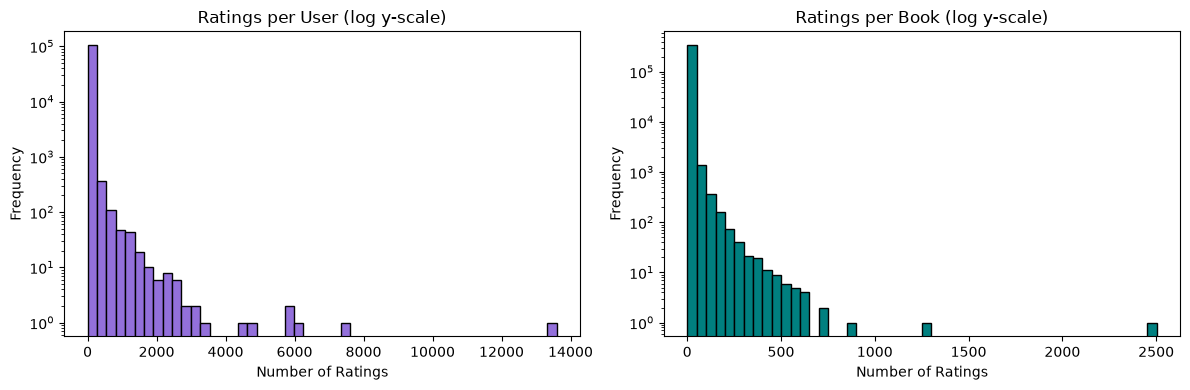

In [6]:
# Ratings per user and per book & Matrix Sparsity
ratings_per_user = b_ratings.groupby('User-ID').size()
ratings_per_book = b_ratings.groupby('ISBN').size()

print('--- Ratings per User (all Bronze ratings) ---')
print(ratings_per_user.describe())
print(f'Users with < 10 ratings: {(ratings_per_user < 10).sum():,} / {len(ratings_per_user):,} ({(ratings_per_user < 10).mean()*100:.2f}%)')

print('\n--- Ratings per Book (all Bronze ratings) ---')
print(ratings_per_book.describe())
print(f'Books with < 10 ratings: {(ratings_per_book < 10).sum():,} / {len(ratings_per_book):,} ({(ratings_per_book < 10).mean()*100:.2f}%)')

n_users_bronze = b_users['User-ID'].nunique()
n_books_bronze = b_books['ISBN'].nunique()
possible_pairs = n_users_bronze * n_books_bronze
density_pct = (len(b_ratings) / possible_pairs) * 100
sparsity_pct = 100 - density_pct
print(f'\nPossible user-book pairs: {possible_pairs:,}')
print(f'Observed ratings: {len(b_ratings):,}')
print(f'Matrix density (filled %): {density_pct:.6f}% | Sparsity: {sparsity_pct:.6f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_per_user.plot(kind='hist', bins=50, logy=True, ax=axes[0], color='mediumpurple', edgecolor='black')
axes[0].set_title('Ratings per User (log y-scale)')
axes[0].set_xlabel('Number of Ratings')

ratings_per_book.plot(kind='hist', bins=50, logy=True, ax=axes[1], color='teal', edgecolor='black')
axes[1].set_title('Ratings per Book (log y-scale)')
axes[1].set_xlabel('Number of Ratings')
plt.tight_layout()
plt.show()

### EDA Findings & Silver Layer Plan

- **Shape, data types and missing-value count:** Users has 278,858 rows (110,762 missing `Age`), Books has 271,360 rows (`Year-Of-Publication` stored as string due to shifted/corrupt rows, plus 2–3 missing authors/publishers/URLs), and Book-Ratings has 1,149,780 rows with 0 nulls — in Silver we will deduplicate, cast `Year-Of-Publication` to numeric, and impute missing ages.
- **Distribution of ratings:** 716,109 out of 1,149,780 ratings (62.28%) are `0` (implicit interactions rather than explicit scores) — in Silver we will remove all `0` ratings and keep only explicit ratings from `1` to `10`.
- **Distribution of user ages and publication years:** User ages contain impossible values (`< 5` and `> 100`, up to 244) and nulls, while publication years contain `0`, future years (`> 2026`), and non-numeric strings — in Silver we will set out-of-range ages (`< 5` or `> 100`) to null and fill with the median age, and set `0`, non-numeric, or future publication years to null.
- **Number of ratings per user and per book:** The vast majority of users (~87.6%) and books (~94.9%) have fewer than 10 total ratings — in Silver we will filter to users and books with at least 10 explicit ratings so collaborative filtering has reliable overlap.
- **Matrix sparsity:** Only ~0.0015% of all possible user-book pairs have a rating (99.9985% sparse) — in Silver we will prune low-activity users/books and in Gold we will store the rating matrix as a `scipy.sparse` CSR matrix.

---
## Step 3: Clean the Data and Build the Silver Layer

We apply all cleaning rules to the Bronze tables and save the cleaned Parquet files to `silver/`:
1. Remove duplicate rows across `users`, `books`, and `book_ratings` (and deduplicate on primary keys `User-ID`, `ISBN`, and `(User-ID, ISBN)`).
2. Remove `0` ratings (implicit) and keep explicit ratings `1`–`10`.
3. Fix user ages: values `< 5` or `> 100` → `NaN`, then fill `NaN` with the median valid age.
4. Split `Location` into `city`, `state`, and `country` columns.
5. Fix `Year-Of-Publication`: coerce to numeric, set `0` or future years (`> 2026`) to `NaN`.
6. Clean text columns (`Book-Title`, `Book-Author`, `Publisher`, `city`, `state`, `country`): strip whitespace, standardize case, and drop `Image-URL-S`, `Image-URL-M`, `Image-URL-L`.
7. Enforce referential integrity: keep only ratings whose `ISBN` and `User-ID` exist in the cleaned `books` and `users` tables.
8. **Threshold choice & justification:** Keep only users and books with **at least 10 explicit ratings** (`MIN_RATINGS = 10`). From our EDA, >87% of users and >94% of books have fewer than 10 ratings, creating extreme sparsity (99.9985%). Setting the threshold to 10 (applied iteratively until both user and book counts converge) removes cold-start noise while retaining ~1,800+ active users, ~2,000+ well-rated books, and >41,000 explicit ratings for reliable cosine similarity.

In [7]:
# 1. Deduplicate
s_users = b_users.drop(columns=['ingestion_timestamp']).drop_duplicates().drop_duplicates(subset=['User-ID']).copy()
s_books = b_books.drop(columns=['ingestion_timestamp']).drop_duplicates().drop_duplicates(subset=['ISBN']).copy()
s_ratings = b_ratings.drop(columns=['ingestion_timestamp']).drop_duplicates().drop_duplicates(subset=['User-ID', 'ISBN']).copy()

# 2. Keep explicit ratings 1..10
s_ratings = s_ratings[(s_ratings['Book-Rating'] >= 1) & (s_ratings['Book-Rating'] <= 10)].copy()

# 3. Fix user ages (< 5 or > 100 -> NaN, fill with median)
s_users.loc[(s_users['Age'] < 5) | (s_users['Age'] > 100), 'Age'] = np.nan
median_age = s_users['Age'].median()
s_users['Age'] = s_users['Age'].fillna(median_age)
print(f'Median valid user age used for imputation: {median_age:.1f}')

# 4. Split Location into city, state, country
loc_parts = s_users['Location'].fillna('').astype(str).str.split(',', n=2, expand=True)
s_users['city'] = loc_parts[0].fillna('').str.strip().str.title()
s_users['state'] = loc_parts[1].fillna('').str.strip().str.title() if loc_parts.shape[1] > 1 else ''
s_users['country'] = loc_parts[2].fillna('').str.strip().str.title() if loc_parts.shape[1] > 2 else ''
s_users = s_users.drop(columns=['Location'])

# 5. Fix publication years (0 or > 2026 -> NaN)
s_books['Year-Of-Publication'] = pd.to_numeric(s_books['Year-Of-Publication'], errors='coerce')
s_books.loc[(s_books['Year-Of-Publication'] <= 0) | (s_books['Year-Of-Publication'] > 2026), 'Year-Of-Publication'] = np.nan
s_books['Year-Of-Publication'] = s_books['Year-Of-Publication'].astype('Int64')

# 6. Clean text columns and drop image URL columns
s_books = s_books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'], errors='ignore')
for col in ['Book-Title', 'Book-Author', 'Publisher']:
    s_books[col] = s_books[col].fillna('Unknown').astype(str).str.strip().str.replace(r'\s+', ' ', regex=True).str.title()
s_books['ISBN'] = s_books['ISBN'].astype(str).str.strip()
s_ratings['ISBN'] = s_ratings['ISBN'].astype(str).str.strip()

# 7. Keep only ratings whose book and user exist in books and users tables
s_ratings = s_ratings[
    s_ratings['User-ID'].isin(s_users['User-ID']) &
    s_ratings['ISBN'].isin(s_books['ISBN'])
].copy()

# 8. Keep only users and books with >= 10 explicit ratings (iterative convergence)
MIN_RATINGS = 10
prev_len = -1
while len(s_ratings) != prev_len:
    prev_len = len(s_ratings)
    user_counts = s_ratings['User-ID'].value_counts()
    s_ratings = s_ratings[s_ratings['User-ID'].isin(user_counts[user_counts >= MIN_RATINGS].index)]
    book_counts = s_ratings['ISBN'].value_counts()
    s_ratings = s_ratings[s_ratings['ISBN'].isin(book_counts[book_counts >= MIN_RATINGS].index)]

s_users = s_users[s_users['User-ID'].isin(s_ratings['User-ID'])].copy()
s_books = s_books[s_books['ISBN'].isin(s_ratings['ISBN'])].copy()

# Save to silver/
s_users.to_parquet('silver/users.parquet', index=False)
s_books.to_parquet('silver/books.parquet', index=False)
s_ratings.to_parquet('silver/book_ratings.parquet', index=False)

print(f'Silver Users:   {s_users.shape}')
print(f'Silver Books:   {s_books.shape}')
print(f'Silver Ratings: {s_ratings.shape}')
print(f'Silver Matrix Density: {len(s_ratings) / (len(s_users) * len(s_books)) * 100:.2f}%')

Median valid user age used for imputation: 32.0


Silver Users:   (1820, 5)
Silver Books:   (2030, 5)
Silver Ratings: (41456, 3)
Silver Matrix Density: 1.12%


---
## Step 4: Build the Gold Layer

From the Silver tables, we create and save the model-ready artifacts in `gold/`:
1. **User-Book Sparse Rating Matrix** (`gold/user_book_rating_matrix.npz`) with index mappings (`gold/user_index.parquet`, `gold/book_index.parquet`).
2. **Book Lookup Table** (`gold/book_lookup.parquet`) mapping `ISBN` to readable `Book-Title`, `Book-Author`, `Year-Of-Publication`, and `Publisher`.
3. **User-Level and Book-Level Aggregates** (`gold/user_aggregates.parquet`, `gold/book_aggregates.parquet`) containing `rating_count` and `avg_rating`.

In [8]:
s_users = pd.read_parquet('silver/users.parquet')
s_books = pd.read_parquet('silver/books.parquet')
s_ratings = pd.read_parquet('silver/book_ratings.parquet')

# 1. Build User-Book sparse rating matrix
user_ids = np.sort(s_ratings['User-ID'].unique())
book_isbns = np.sort(s_ratings['ISBN'].unique())

user_to_idx = {uid: idx for idx, uid in enumerate(user_ids)}
isbn_to_idx = {isbn: idx for idx, isbn in enumerate(book_isbns)}

row_idx = s_ratings['User-ID'].map(user_to_idx).to_numpy()
col_idx = s_ratings['ISBN'].map(isbn_to_idx).to_numpy()
values = s_ratings['Book-Rating'].to_numpy(dtype=np.float32)

user_book_matrix = sparse.csr_matrix(
    (values, (row_idx, col_idx)),
    shape=(len(user_ids), len(book_isbns))
)

sparse.save_npz('gold/user_book_rating_matrix.npz', user_book_matrix)
pd.DataFrame({'user_idx': np.arange(len(user_ids)), 'User-ID': user_ids}).to_parquet('gold/user_index.parquet', index=False)
pd.DataFrame({'book_idx': np.arange(len(book_isbns)), 'ISBN': book_isbns}).to_parquet('gold/book_index.parquet', index=False)

# 2. Book lookup table
book_lookup = s_books[['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher']].copy()
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)

# 3. User-level and Book-level aggregates
user_agg = (
    s_ratings.groupby('User-ID', as_index=False)
    .agg(rating_count=('Book-Rating', 'count'), avg_rating=('Book-Rating', 'mean'))
)
user_agg['avg_rating'] = user_agg['avg_rating'].round(3)
user_agg.to_parquet('gold/user_aggregates.parquet', index=False)

book_agg = (
    s_ratings.groupby('ISBN', as_index=False)
    .agg(rating_count=('Book-Rating', 'count'), avg_rating=('Book-Rating', 'mean'))
    .merge(book_lookup[['ISBN', 'Book-Title', 'Book-Author']], on='ISBN', how='left')
)
book_agg['avg_rating'] = book_agg['avg_rating'].round(3)
book_agg.to_parquet('gold/book_aggregates.parquet', index=False)

print(f'Gold sparse matrix shape: {user_book_matrix.shape}, nnz={user_book_matrix.nnz:,}')
print('Top 5 most-rated books in Gold:')
print(book_agg.sort_values('rating_count', ascending=False).head(5)[['Book-Title', 'Book-Author', 'rating_count', 'avg_rating']].to_string(index=False))

Gold sparse matrix shape: (1820, 2030), nnz=41,456
Top 5 most-rated books in Gold:
                                                      Book-Title   Book-Author  rating_count  avg_rating
                                       The Lovely Bones: A Novel  Alice Sebold           223       8.238
                                               The Da Vinci Code     Dan Brown           177       8.610
                             The Red Tent (Bestselling Backlist) Anita Diamant           132       8.492
                                         The Secret Life Of Bees Sue Monk Kidd           125       8.664
Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback)) J. K. Rowling           119       9.042


---
## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

1. Load the sparse rating matrix from `gold/` and transpose it so each row is a **book** and each column is a **user**.
2. Fit `NearestNeighbors(metric='cosine', algorithm='brute')` on the sparse book-user matrix.
3. Implement `get_similar_books(book_title, n=10)` to return the 10 most similar books to a given title.
4. Implement `recommend(user_id, n=10)` which identifies books the user rated highly, finds their most similar books, weights similarity by the user's rating, filters out books the user has already read, and returns the top `n` titles.

In [9]:
# 1. Load Gold artifacts and transpose matrix (rows = books, cols = users)
gold_matrix = sparse.load_npz('gold/user_book_rating_matrix.npz')
user_index_df = pd.read_parquet('gold/user_index.parquet')
book_index_df = pd.read_parquet('gold/book_index.parquet')
book_lookup_df = pd.read_parquet('gold/book_lookup.parquet')
book_agg_df = pd.read_parquet('gold/book_aggregates.parquet')

book_meta = (
    book_index_df
    .merge(book_lookup_df, on='ISBN', how='left')
    .merge(book_agg_df[['ISBN', 'rating_count', 'avg_rating']], on='ISBN', how='left')
)

user_id_to_idx = dict(zip(user_index_df['User-ID'], user_index_df['user_idx']))
book_user_matrix = gold_matrix.T.tocsr()

# 2. Fit NearestNeighbors with cosine similarity
nn_model = NearestNeighbors(metric='cosine', algorithm='brute')
nn_model.fit(book_user_matrix)
print(f'NearestNeighbors fitted on book-user matrix of shape {book_user_matrix.shape}')

NearestNeighbors fitted on book-user matrix of shape (2030, 1820)


In [10]:
# 3. Function: 10 most similar books given a book title
def get_similar_books(book_title: str, n: int = 10) -> pd.DataFrame:
    title_clean = book_title.strip().lower()
    exact_matches = book_meta[book_meta['Book-Title'].str.lower() == title_clean]
    if exact_matches.empty:
        partial_matches = book_meta[book_meta['Book-Title'].str.lower().str.contains(title_clean, regex=False, na=False)]
        if partial_matches.empty:
            raise ValueError(f"Book title '{book_title}' not found in Gold layer.")
        anchor = partial_matches.sort_values('rating_count', ascending=False).iloc[0]
    else:
        anchor = exact_matches.sort_values('rating_count', ascending=False).iloc[0]

    anchor_idx = int(anchor['book_idx'])
    distances, indices = nn_model.kneighbors(book_user_matrix[anchor_idx], n_neighbors=min(n + 15, book_user_matrix.shape[0]))

    results = []
    seen_titles = {anchor['Book-Title'].lower()}
    for dist, idx in zip(distances.flatten(), indices.flatten()):
        if idx == anchor_idx:
            continue
        row = book_meta.iloc[idx]
        t_low = row['Book-Title'].lower()
        if t_low in seen_titles:
            continue
        seen_titles.add(t_low)
        results.append({
            'ISBN': row['ISBN'],
            'Book-Title': row['Book-Title'],
            'Book-Author': row['Book-Author'],
            'Similarity': round(float(1.0 - dist), 4),
            'Avg-Rating': row['avg_rating'],
            'Rating-Count': int(row['rating_count'])
        })
        if len(results) >= n:
            break
    return pd.DataFrame(results)


# 4. Function: recommend(user_id, n=10)
def recommend(user_id: int, n: int = 10, high_rating_threshold: float = 7.0) -> pd.DataFrame:
    if user_id not in user_id_to_idx:
        raise ValueError(f'User-ID {user_id} not found in Gold layer.')

    u_idx = user_id_to_idx[user_id]
    user_row = gold_matrix[u_idx]
    rated_book_indices = user_row.indices
    rated_scores = user_row.data

    # Identify books the user rated highly (fallback to top-rated if none >= threshold)
    high_mask = rated_scores >= high_rating_threshold
    if not np.any(high_mask):
        top_k = np.argsort(-rated_scores)[:5]
        liked_indices = rated_book_indices[top_k]
        liked_ratings = rated_scores[top_k]
    else:
        liked_indices = rated_book_indices[high_mask]
        liked_ratings = rated_scores[high_mask]

    read_isbns = set(book_meta.iloc[rated_book_indices]['ISBN'])
    read_titles = set(book_meta.iloc[rated_book_indices]['Book-Title'].str.lower())

    candidate_scores = {}
    for b_idx, u_rating in zip(liked_indices, liked_ratings):
        distances, indices = nn_model.kneighbors(book_user_matrix[b_idx], n_neighbors=min(25, book_user_matrix.shape[0]))
        for dist, nbr_idx in zip(distances.flatten(), indices.flatten()):
            if nbr_idx == b_idx:
                continue
            sim = 1.0 - float(dist)
            if sim <= 0:
                continue
            candidate_scores[nbr_idx] = candidate_scores.get(nbr_idx, 0.0) + sim * float(u_rating)

    ranked = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
    recs = []
    seen_titles = set(read_titles)
    for nbr_idx, score in ranked:
        row = book_meta.iloc[nbr_idx]
        if row['ISBN'] in read_isbns or row['Book-Title'].lower() in seen_titles:
            continue
        seen_titles.add(row['Book-Title'].lower())
        recs.append({
            'ISBN': row['ISBN'],
            'Book-Title': row['Book-Title'],
            'Book-Author': row['Book-Author'],
            'Weighted-Score': round(score, 4),
            'Avg-Rating': row['avg_rating']
        })
        if len(recs) >= n:
            break
    return pd.DataFrame(recs)

---
## Step 6: Demo and Sanity Check

We test `get_similar_books()` on a popular book title, and run `recommend()` for **three different users**, displaying each user's highly rated books alongside their top 10 recommended books.

In [11]:
# Sanity check 1: Similar books for a well-known title
sample_title = 'The Da Vinci Code'
print(f"Top 10 books similar to '{sample_title}':")
print(get_similar_books(sample_title, n=10).to_string(index=False))

Top 10 books similar to 'The Da Vinci Code':
      ISBN                Book-Title        Book-Author  Similarity  Avg-Rating  Rating-Count
0671027360       Angels &Amp; Demons          Dan Brown      0.2398       8.162            99
0316666343 The Lovely Bones: A Novel       Alice Sebold      0.1783       8.238           223
0316155306      The Narrows: A Novel   Michael Connelly      0.1763       8.000            11
0374199698        Middlesex: A Novel  Jeffrey Eugenides      0.1749       8.310            29
0316780812        Sea Glass: A Novel       Anita Shreve      0.1616       8.583            12
0525947299          No Second Chance       Harlan Coben      0.1599       8.684            19
0553802488                  The Face        Dean Koontz      0.1575       8.417            12
0446531332        Nights In Rodanthe    Nicholas Sparks      0.1560       7.909            33
0142001740   The Secret Life Of Bees      Sue Monk Kidd      0.1556       8.664           125
0345452577     

In [12]:
# Sanity check 2: Recommendations for 3 different users
user_agg_df = pd.read_parquet('gold/user_aggregates.parquet')
sample_users = (
    user_agg_df[user_agg_df['rating_count'].between(15, 40)]
    .sort_values('avg_rating', ascending=False)
    .iloc[[0, 50, 150]]['User-ID']
    .tolist()
)

for uid in sample_users:
    u_idx = user_id_to_idx[uid]
    u_row = gold_matrix[u_idx]
    liked_df = pd.DataFrame({
        'Book-Title': book_meta.iloc[u_row.indices]['Book-Title'].values,
        'Book-Author': book_meta.iloc[u_row.indices]['Book-Author'].values,
        'User-Rating': u_row.data
    }).sort_values('User-Rating', ascending=False)

    recs_df = recommend(uid, n=10)

    print('=' * 90)
    print(f'USER {uid} | Total Gold Ratings: {len(liked_df)}')
    print('\n--- Books User Rated Highly (Top 10) ---')
    print(liked_df.head(10).to_string(index=False))
    print('\n--- Top 10 Recommended Books ---')
    print(recs_df[['Book-Title', 'Book-Author', 'Weighted-Score', 'Avg-Rating']].to_string(index=False))
    print()

USER 277523 | Total Gold Ratings: 15

--- Books User Rated Highly (Top 10) ---
                          Book-Title        Book-Author  User-Rating
Ten Big Ones: A Stephanie Plum Novel    Janet Evanovich         10.0
                          3Rd Degree    James Patterson         10.0
                          2Nd Chance    James Patterson         10.0
                 The Conspiracy Club Jonathan Kellerman         10.0
                             Therapy Jonathan Kellerman         10.0
                   The King Of Torts       John Grisham         10.0
                      The Last Juror       John Grisham         10.0
                   The King Of Torts       John Grisham         10.0
                        Split Second     David Baldacci         10.0
                         Hemlock Bay  Catherine Coulter         10.0

--- Top 10 Recommended Books ---
                                Book-Title        Book-Author  Weighted-Score  Avg-Rating
                      The Narrows: A N